In [1]:
import torch
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

In [ ]:
OUT_DIR = Path("results/run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026")

In [2]:
results_no_nodes = torch.load(
    r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\explanations_none_object.pth",
    map_location="cpu",
    weights_only=False
)

In [3]:
df_results_no_nodes = pd.DataFrame(results_no_nodes)

In [4]:
results_nodes = torch.load(
    r"results\run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026\explanations_attributes_object.pth",
    map_location="cpu",
    weights_only=False
)

In [5]:
df_results_nodes = pd.DataFrame(results_nodes)

In [6]:
def gini_coefficient(values):
    values = np.sort(np.asarray(values, dtype=float))

    n = len(values)

    if n == 0:
        return np.nan

    if np.sum(values) == 0:
        return 0.0

    return (
        2 * np.sum(np.arange(1, n + 1) * values)
        / (n * np.sum(values))
        - (n + 1) / n
    )


def summarize_edge_masks(df):

    rows = []

    for _, row in df.iterrows():

        mask = row["edge_mask"]

        if mask is None:
            continue

        values = mask.detach().cpu().numpy().flatten()

        if len(values) == 0:
            continue

        rows.append({
            "row": row["row"],
            "num_edges": len(values),
            "mean": np.mean(values),
            "std": np.std(values),
            "gini": gini_coefficient(values),
            "p90_p10": np.percentile(values, 90) - np.percentile(values, 10),
        })

    stats = pd.DataFrame(rows)

    # Aggregate summary
    print("\nSummary across all graphs:")
    print(
        stats[
            ["mean", "std", "gini", "p90_p10"]
        ].describe().round(3)
    )

    # Visualize
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    metrics = [
        ("std", "Standard deviation"),
        ("gini", "Gini coefficient"),
        ("p90_p10", "90th–10th percentile difference"),
    ]

    for ax, (metric, title) in zip(axes, metrics):

        sns.histplot(
            data=stats,
            x=metric,
            bins=25,
            kde=True,
            ax=ax,
        )

        ax.set_title(title)
        ax.set_ylabel("Number of graphs")

    plt.tight_layout()
    plt.show()

    return stats


Summary across all graphs:
          mean      std     gini  p90_p10
count  360.000  360.000  360.000  360.000
mean     0.151    0.089    0.166    0.116
std      0.081    0.097    0.145    0.226
min      0.082    0.002    0.015    0.002
25%      0.113    0.017    0.055    0.020
50%      0.122    0.021    0.065    0.024
75%      0.144    0.155    0.275    0.032
max      0.525    0.371    0.513    0.816


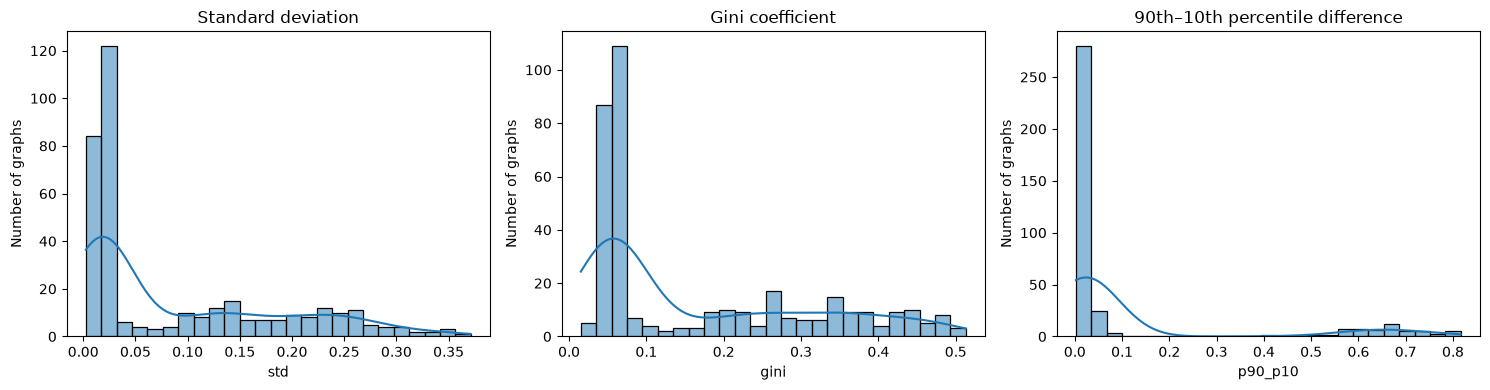

,row,num_edges,mean,std,gini,p90_p10
0,13,211,0.109410,0.010234,0.039895,0.018480
1,17,361,0.117684,0.018418,0.057058,0.021306
2,20,306,0.115315,0.018265,0.058330,0.020594
3,22,313,0.115925,0.017893,0.055152,0.020776
4,28,398,0.121092,0.016442,0.054432,0.024530
...,...,...,...,...,...,...
355,2372,57,0.373368,0.371205,0.499095,0.808040
356,2379,175,0.420350,0.297135,0.384054,0.656307
357,2381,205,0.146666,0.153881,0.275727,0.030479
358,2383,125,0.131266,0.142060,0.256212,0.019708


In [7]:
summarize_edge_masks(df_results_no_nodes)


Summary across all graphs:
          mean      std     gini  p90_p10
count  360.000  360.000  360.000  360.000
mean     0.113    0.021    0.064    0.027
std      0.014    0.024    0.051    0.052
min      0.087    0.002    0.014    0.003
25%      0.103    0.013    0.042    0.014
50%      0.112    0.017    0.054    0.020
75%      0.121    0.019    0.062    0.024
max      0.189    0.283    0.499    0.858


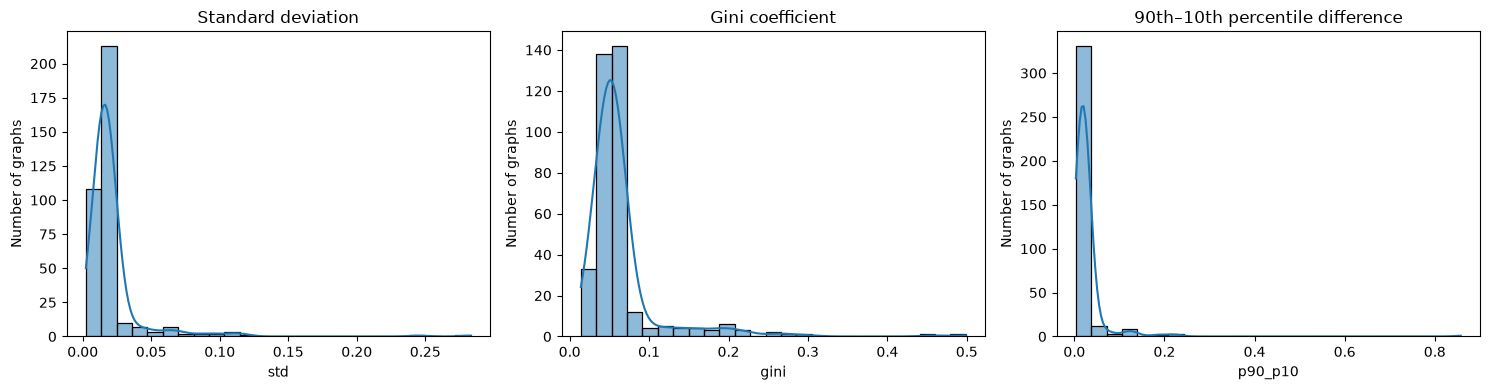

,row,num_edges,mean,std,gini,p90_p10
0,13,211,0.120863,0.029451,0.097454,0.042676
1,17,361,0.117515,0.018602,0.059508,0.023268
2,20,306,0.115117,0.018323,0.059132,0.022379
3,22,313,0.117129,0.018293,0.057316,0.022976
4,28,398,0.121314,0.016204,0.051996,0.022452
...,...,...,...,...,...,...
355,2372,57,0.099297,0.113129,0.171554,0.004097
356,2379,175,0.103089,0.018550,0.057573,0.016127
357,2381,205,0.107896,0.014530,0.046248,0.016827
358,2383,125,0.097290,0.013324,0.043589,0.013575


In [8]:
summarize_edge_masks(df_results_nodes)